# Train Mask R-CNN R50-FPN v2 (torchvision)

Thin runner over `iiss.models.maskrcnn.train` (same code as `python -m iiss.train --run configs/runs/maskrcnn_s<S>_seed42.yaml`). One notebook execution = one run; change only the parameters cell to launch another S.

- Run order (priority): the S=640 baseline first, then S=320 and S=960 (`.agent/experiments.md`).
- The 2-hour cap is cumulative per run id over all sessions, including hard kills (logged as `killed`). A capped or stopped run is continued with `RESUME = True`; a fresh start refuses to overwrite an existing `weights/last.pt`.
- The evaluated checkpoint is `weights/last.pt`; `best.pt` is logged only.
- Keep the outputs of this notebook after a real run: they are process evidence.
- `SMOKE = True`: 16 train / 8 valid images, S=320, 2 epochs, 5-minute cap, written to `runs/smoke/`.
- Keep the laptop plugged in and awake; close other GPU programs.

## Parameters

In [1]:
MODEL = 'maskrcnn'
S = 960              # 320 / 640 / 960 -> configs/runs/maskrcnn_s<S>_seed<SEED>.yaml
SEED = 42
RESUME = False       # True: continue from weights/last.pt (after a stop, crash or cap)
RUNS_ROOT = None     # None = runs/ in the repo (override, e.g. Google Drive on Colab)
SMOKE = False

## Config

In [2]:
import importlib

import pandas as pd
import torch
from IPython.display import display

from iiss.analysis.training import (config_table, gpu_sessions, notebook_config,
                                    plot_history, run_summary)
from iiss.models.common import run_dir
from iiss.utils.log import setup_logging

setup_logging()
cfg = notebook_config(MODEL, S, SEED, smoke=SMOKE, runs_root=RUNS_ROOT)
print(torch.__version__, torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')
config_table(cfg)

2.14.1+cu126 NVIDIA GeForce RTX 4050 Laptop GPU


,value
run_id,maskrcnn_s960_seed42
input_size,960
time_cap_hours,2.0
run_dir,C:\Users\Syauqi Nabil\Lectures\University\Seme...
train.epochs,24
train.batch,2
train.accumulate,1
train.base_lr,0.0025
train.base_batch,2
train.momentum,0.9


## Status before training

In [3]:
pd.Series(run_summary(cfg)).to_frame('value')

,value
run_id,maskrcnn_s960_seed42
run_dir,C:\Users\Syauqi Nabil\Lectures\University\Seme...
last_pt,False
best_pt,False
epochs_done,0
epochs_planned,24
sessions,0
statuses,
gpu_hours_used,0.0
cap_hours,2.0


## Train

Logs stream below. Interrupting the kernel stops the run safely (state of the last finished epoch is kept).

In [4]:
module = importlib.import_module(f'iiss.models.{MODEL}')
out = module.train(cfg, resume=RESUME)
out

2026-11-24 01:57:18 INFO    iiss.utils.env: Wrote environment snapshot to C:\Users\Syauqi Nabil\Lectures\University\Semester 5\Computer Vision\Task\Instance Segmentation\indoor-instance-seg-shift\runs\maskrcnn_s960_seed42\env.json


2026-11-24 01:57:18 INFO    iiss.utils.seed: Seeded everything with seed=42 (deterministic=False)


2026-11-24 01:57:22 INFO    iiss.models.torch_loop: Training maskrcnn_s960_seed42: 397 images, S=960, 24 epochs, batch 2 x accumulate 1 (lr 0.0025), 199 steps/epoch, AMP=torch.float16


2026-11-24 01:57:22 INFO    iiss.utils.timer: Timer started for maskrcnn_s960_seed42: budget 7200 s, already used 0 s, remaining 7200 s


C:\Users\Syauqi Nabil\Lectures\University\Semester 5\Computer Vision\Task\Instance Segmentation\indoor-instance-seg-shift\src\iiss\models\torch_loop.py:282: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


2026-11-24 01:58:40 INFO    iiss.models.torch_loop: Epoch 1/24: loss 2.8442, valid mask AP -, 78 s


... (2,059 outputs left out)

2026-11-24 02:36:05 INFO    iiss.models.torch_loop: New best valid mask AP 0.1784 at epoch 24


2026-11-24 02:36:06 INFO    iiss.models.torch_loop: Epoch 24/24: loss 0.4259, valid mask AP 0.17844, 128 s


2026-11-24 02:36:06 INFO    iiss.utils.timer: Timer stopped for maskrcnn_s960_seed42: 2324.0 s this session, status=completed, peak VRAM 3916.0 MB


WindowsPath('C:/Users/Syauqi Nabil/Lectures/University/Semester 5/Computer Vision/Task/Instance Segmentation/indoor-instance-seg-shift/runs/maskrcnn_s960_seed42')

## Result

GPU time per session (`runs/gpu_time_log.csv`), run status and training curves (also saved as `<run_dir>/curves.png`). The validation curve of YOLO is Ultralytics' validator; the comparable numbers come from `predict_and_evaluate.ipynb`.

,run_id,start,end,wall_clock_s,gpu_name,peak_vram_mb,cap_hit,status
0,maskrcnn_s960_seed42,2026-11-24T01:57:22+07:00,2026-11-24T02:36:06+07:00,2324.0,NVIDIA GeForce RTX 4050 Laptop GPU,3916.0,False,completed


,value
run_id,maskrcnn_s960_seed42
run_dir,C:\Users\Syauqi Nabil\Lectures\University\Seme...
last_pt,True
best_pt,True
epochs_done,24
epochs_planned,24
sessions,1
statuses,completed
gpu_hours_used,0.646
cap_hours,2.0


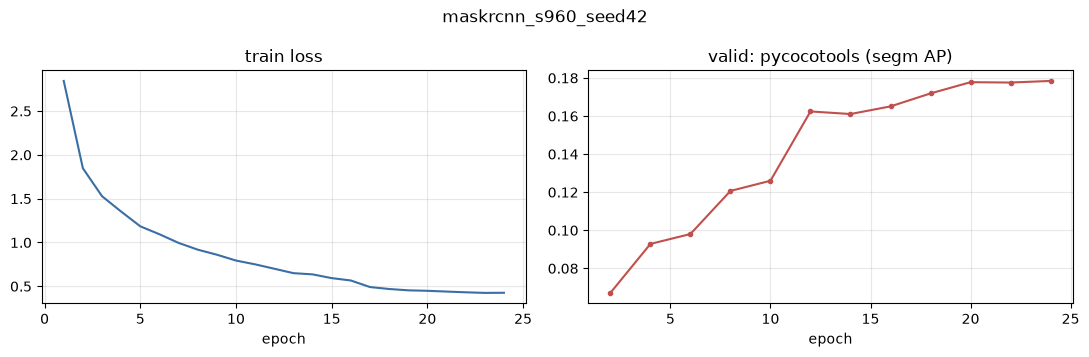

In [5]:
display(gpu_sessions(cfg))
display(pd.Series(run_summary(cfg)).to_frame('value'))
fig = plot_history(cfg, save_to=run_dir(cfg) / 'curves.png')

## Next step

Send back the summary table above (run id, epochs, GPU hours, last/best valid metric). Then run the next S, or `predict_and_evaluate.ipynb`.